# Does a change between recordings survive moving the mite?

**The question:** `dead_mite_change.ipynb` found that a dead mite's image does not change from one recording to the next, and a live one's does, even when it is labelled still in both (AUC 0.98). That holds while nobody touches the box. To get ground truth the box is opened, and the mites are poked or brushed: between two recordings a dead mite may then lie a few pixels elsewhere and turned. Which measure of the change between two recordings still tells a live mite from a dead one when the mites have been moved?

**The test:** the long run (every mite labelled in every recording) is used as it is and moved on purpose. In every recording each mite is moved as a rigid body by a fresh random amount (`scripts/moved_mite_change.py`, `move()`), in five conditions:

- **untouched**: as recorded,
- **shifted**: by 2 to 6 whole pixels, in any direction,
- **turned**: by a quarter, half or three quarters of a turn (or not), about the patch's centre,
- **moved**: both, what opening the box may do,
- **moved, any angle**: shifted by any fraction of a pixel and turned by any angle.

Whole pixels and quarter turns move the pixels as they are. A real move gives the camera a fresh picture of the mite; a move by any angle has to be interpolated, which blurs what is finer than a pixel, the legs above all (on 60 long-dead pairs, a turn of 37 degrees left the tracker 0.65 legs a recording where it found 1.28, and a quarter turn 1.37). So the four first conditions are the test, and *moved, any angle* is what a real move costs at most: its blur is the simulation's, not the camera's.

So every pair of recordings sees a move, and the mites that were dead stay dead: a measure that is fooled by the move makes them look alive.

**The measures**, each comparing a mite's recording with the next:

| measure | what it compares | why it could survive a move |
|---|---|---|
| `image_change` | the mean images, the plate's shift (the median over the mites) taken out: `classes/recording_change.py` as it is | it does not: the baseline |
| `aligned_change` | the mean images after each mite is laid on itself (its own shift and turn: a turn every 10 degrees, then ECC), over the mite and 3 px around it | the move is undone |
| `outline_change` | the outline as rays from the mite's centre, shape only (size and shift taken out), at the turn that fits best | no position in it, the turn is searched |
| `leg_shift` | the legs `classes/leg_tracker.py` finds, their places in the body's own frame, paired with those of the recording before: the largest distance of a pair (and `leg_shift_median`, the median) | a leg's place on the body does not depend on where the body is |

The light falls off across the plate, so a mite pushed elsewhere lies on brighter or darker plate. The three new measures read the mite's darkness against the plate in a ring 6 to 10 px around its body, not against the edge of the patch: on one mite with a faint shadow beside it, the edge made a 4 px shift of a dead mite look like a change five times its noise.

Alive and dead are taken from the labels, as in `dead_mite_change.ipynb`: a pair is **alive** when both recordings are up to the mite's last labelled movement, **dead** when both are 500 minutes or more after it, **long dead** from 1000 minutes. The mites never labelled moving are left out.

The script cuts the patches once into the system's temporary folder and keeps the measures in `results/scripts/`, so this notebook reruns in seconds once the script has run (`python scripts/moved_mite_change.py`, about 15 minutes the first time).

## Findings (run of 19 October 2026)

One run, one plate, 59 mites; 3765 alive pairs of recordings, 10150 dead ones. *Moved* is shifted by 2 to 6 whole pixels and turned by quarter turns; *any angle* is the pessimistic case (see above).

- **The change in use today does not survive a move.** `image_change` tells alive from dead with an AUC of 0.983 untouched and 0.48 moved: every dead pair looks changed (100%). Left as it is, the pair across an opening would make every dead mite look alive.
- **The outline does not see the move at all.** `outline_change` has an AUC of 0.974 untouched and 0.973 moved (0.963 and 0.962 for alive pairs labelled still against long-dead ones). At the limit 99% of the untouched dead pairs stay under, 1.1% of the moved dead pairs look changed (1% untouched), and it catches 81% of the alive pairs either way. Not moving the mite at all costs it 0.01 of AUC against `image_change`. It reads the mite alone: its body is the dark piece nearest the patch's centre, and its outline only what is within 6 px of it. Before that, one mite with a neighbour at the edge of its patch looked changed in almost every moved pair.
- **It goes on seeing the mites change after their last labelled movement**, as `image_change` does (55% of the pairs in the first 100 minutes, 19% from 100 to 200, about 11% up to 500, 6% to 700, 1% from 1000 on; `image_change` 54%, 18%, 10 to 12%, 6%, 1%), and its survival curve runs behind the labels': LT50 11.5 hours against 8.0, the death 7 recordings (70 minutes) later in the middle, more than 6 hours later for a quarter of the mites (see *Every mite, and the survival*). The mites hardly move from their place in that time (0.05 px and 0.3 degrees in the middle; none by more than a pixel): what changes is their outline, the legs.
- **Laying the image on itself undoes a turn but not quite a shift.** The alignment finds the turn to within 5 degrees in 99% of the pairs, and `aligned_change` loses nothing to a turn, but a shift takes it from 0.94 to 0.89, and 10% of the moved dead pairs look changed. It is also the weaker of the two untouched.
- **The legs survive a shift, not quite a turn, and say nothing about a third of the dead pairs.** `leg_shift` keeps its AUC under a shift (0.914, 0.916) and loses some to a turn (0.87): the body's axis, which the legs are turned by, is not exact. A leg is found in both recordings of 66% of the dead pairs only. And it ranks better than it calls: 1% of the untouched dead pairs reach 2.1 px (a leg found in one recording paired with another one), so at the limit that keeps 99% of the dead pairs it catches 3% of the alive ones.
- **Interpolated, every measure loses.** Moved by any angle: `outline_change` 0.847, `aligned_change` 0.746, `leg_shift` 0.679, and the legs found in both recordings drop from 66% to 36% of the dead pairs. That is the blur of the simulation's interpolation, which a camera taking a fresh picture does not add: a real move costs somewhere between *moved* and this.

**What follows:** `outline_change` is the measure to take between recordings when the box may be opened: it needs no leg found, nothing warped, and a move by whole pixels and quarter turns changes nothing in it. The pair across an opening should still be left out (see below), and a run with dead mites nudged on purpose is the test that counts before it is used.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import moved_mite_change as mmc
from classes.leg_tracker import LegTracker

# The project's reporting module switches matplotlib to Agg (no figures) on import.
%matplotlib inline

# Chart style, as in death_time_calibration.ipynb: thin marks, recessive axes and grid, text in ink colours.
BLUE, ORANGE, AQUA, GREY, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8d8c85", "#7d5bd0"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3dc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
CONDITION_COLORS = dict(zip(mmc.CONDITIONS, [GREY, AQUA, VIOLET, ORANGE, "#b8456b"]))
SHOWN = ("untouched", "moved", mmc.ANY_ANGLE)
UNITS = {"image_change": "grey levels", "aligned_change": "grey levels", "outline_change": "px",
         "leg_shift": "px", "leg_shift_median": "px"}
pd.set_option("display.precision", 3)

## The run

In [2]:
run = mmc.load_run()
found = mmc.measures(run)
group = mmc.pairs(run)
n_mites, n_recordings = run["moving"].shape
print(f"{run['name']}: {n_mites} mites, {n_recordings} recordings {np.median(np.diff(run['times'])):g} minutes apart")
print("pairs of recordings:", ", ".join(f"{name} {int(mask.sum())}" for name, mask in group.items()))

test_run_2026-09-08_Mathis_last_dsRNA: 59 mites, 295 recordings 10 minutes apart
pairs of recordings: alive 3765, waiting 2843, dead 10150, long_dead 7361, alive_still 2459


## Alive or dead, moved or not

For each measure and condition:

- **AUC alive / dead**: the chance an alive pair changes more than a dead one (1 tells them apart fully, 0.5 not at all).
- **AUC alive still / long dead**: the same for the hardest alive pairs (labelled still in both recordings) against the surest dead ones.
- **dead over the limit**: the share of dead pairs that look changed. The limit of a measure is what 99% of its *untouched* dead pairs stay under, so it is 1% untouched by construction: what it grows to is what the move costs.
- **alive over the limit**: the share of alive pairs caught at that limit.
- **measured**: the share of pairs the measure says anything about (the legs need a leg found in both recordings).

In [3]:
table = mmc.summary(found, group)
display(table.style.format("{:.3f}", subset=["AUC alive / dead", "AUC alive still / long dead"])
        .format("{:.1%}", subset=["dead over the limit", "alive over the limit", "measured, dead", "measured, alive"])
        .background_gradient(cmap="RdYlGn", subset=["AUC alive / dead", "AUC alive still / long dead"], vmin=0.5, vmax=1)
        .background_gradient(cmap="RdYlGn_r", subset=["dead over the limit"], vmin=0, vmax=0.5))

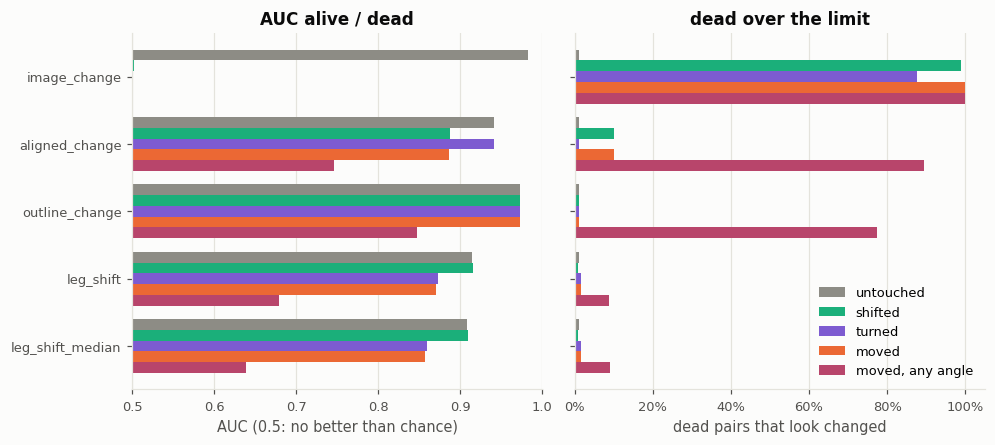

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, gridspec_kw={"wspace": 0.08})
width = 0.8 / len(mmc.CONDITIONS)
for ax, column in zip(axes, ["AUC alive / dead", "dead over the limit"]):
    for index, condition in enumerate(mmc.CONDITIONS):
        values = [table.loc[(measure, condition), column] for measure in mmc.MEASURES]
        ax.barh(np.arange(len(mmc.MEASURES)) + (index - (len(mmc.CONDITIONS) - 1) / 2) * width, values, height=width,
                color=CONDITION_COLORS[condition], label=condition)
    ax.set_title(column)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(mmc.MEASURES)), mmc.MEASURES)
axes[0].invert_yaxis()
axes[0].set_xlim(0.5, 1)
axes[0].set_xlabel("AUC (0.5: no better than chance)")
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].set_xlabel("dead pairs that look changed")
axes[1].legend(loc="lower right")
plt.show()

## The changes, left alone and moved

Each row a measure: the change of the dead and of the alive pairs, untouched, moved, and moved by any angle. The dashed line is the measure's limit. A measure that survives the move looks the same on both sides.

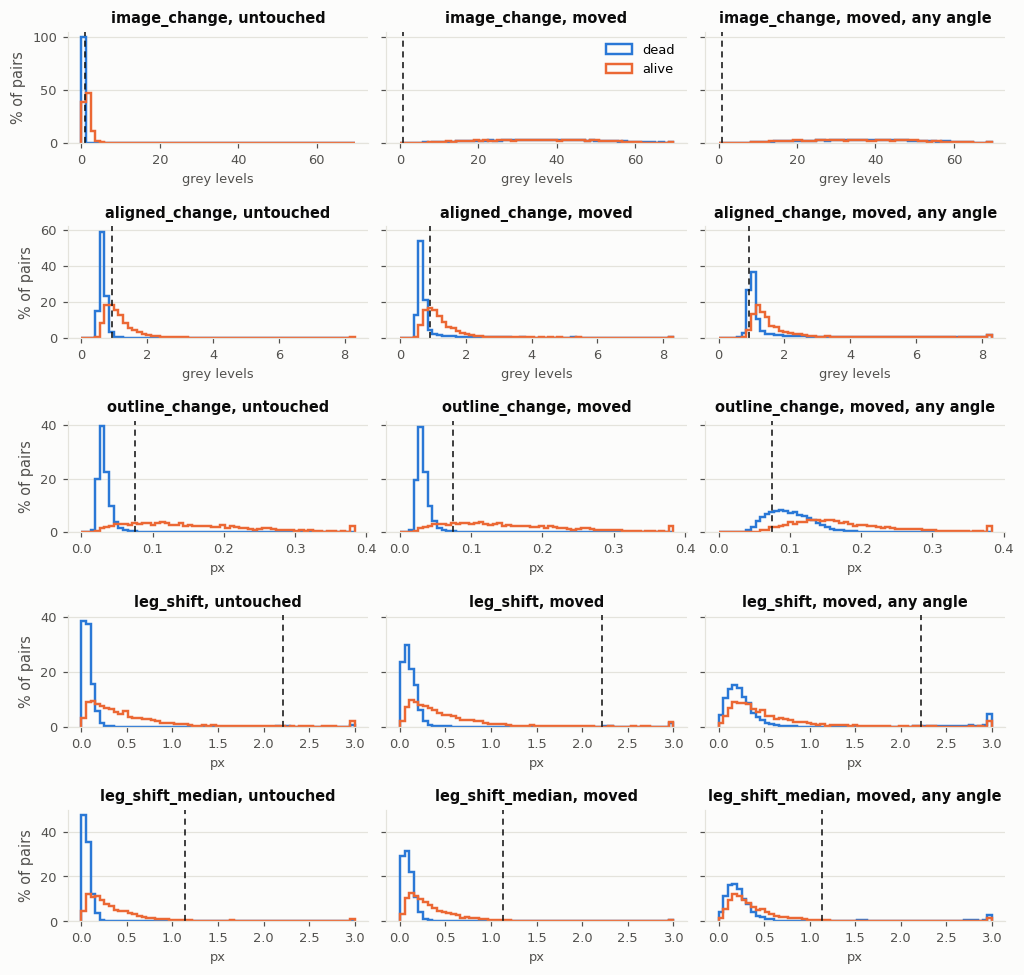

In [5]:
fig, axes = plt.subplots(len(mmc.MEASURES), len(SHOWN), figsize=(11, 2.1 * len(mmc.MEASURES)), sharey="row",
                         gridspec_kw={"hspace": 0.75, "wspace": 0.06})
for row, measure in enumerate(mmc.MEASURES):
    every = np.concatenate([found[c][measure][group[g]] for c in SHOWN for g in ("dead", "alive")])
    every = every[np.isfinite(every)]
    bins = np.linspace(0, np.percentile(every, 99.5), 60)
    limit = np.nanpercentile(found["untouched"][measure][group["dead"]], 99)
    for column, condition in enumerate(SHOWN):
        ax = axes[row, column]
        for name, color in (("dead", BLUE), ("alive", ORANGE)):
            values = found[condition][measure][group[name]]
            values = np.clip(values[np.isfinite(values)], None, bins[-1])
            ax.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)), histtype="step",
                    color=color, linewidth=1.6, label=name)
        ax.axvline(limit, color=INK, linewidth=1, linestyle=(0, (4, 3)))
        ax.set_title(f"{measure}, {condition}", fontsize=9.5)
        ax.set_xlabel(UNITS[measure], fontsize=8.5)
        ax.grid(axis="x", visible=False)
    axes[row, 0].set_ylabel("% of pairs")
axes[0, 1].legend()
plt.show()

## Does the alignment find the move?

`aligned_change` lays each mite on itself. In the conditions with a turn the turn between two recordings is known (the difference of the two turns applied), so the turn the alignment found can be checked. A dead mite's turn should be found to a few degrees; one found half a circle off is a mite laid on itself the wrong way round.

turned, dead: turn found within 5 degrees in 100.0%, half a circle off (over 150 degrees) in 0.0%
turned, alive: turn found within 5 degrees in 99.6%, half a circle off (over 150 degrees) in 0.0%
moved, dead: turn found within 5 degrees in 99.9%, half a circle off (over 150 degrees) in 0.0%
moved, alive: turn found within 5 degrees in 99.2%, half a circle off (over 150 degrees) in 0.1%
moved, any angle, dead: turn found within 5 degrees in 99.8%, half a circle off (over 150 degrees) in 0.0%
moved, any angle, alive: turn found within 5 degrees in 99.3%, half a circle off (over 150 degrees) in 0.0%


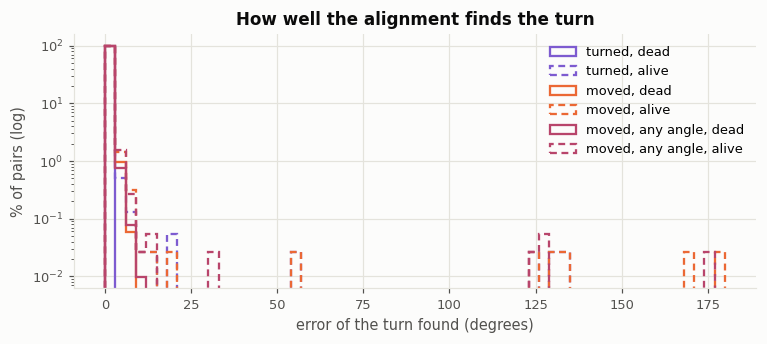

In [6]:
def turn_error(condition):
    applied = np.array([np.diff(mmc.poses(condition, n_recordings, mite)[:, 2]) for mite in range(n_mites)])
    # the alignment turns the later image back onto the earlier: the opposite of what was applied
    return (found[condition]["turn"] + applied + 180) % 360 - 180

fig, ax = plt.subplots(figsize=(8, 3))
for condition in ("turned", "moved", mmc.ANY_ANGLE):
    error = turn_error(condition)
    for name, linestyle in (("dead", "-"), ("alive", (0, (3, 2)))):
        values = np.abs(error[group[name]])
        print(f"{condition}, {name}: turn found within 5 degrees in {np.mean(values < 5):.1%}, "
              f"half a circle off (over 150 degrees) in {np.mean(values > 150):.1%}")
        ax.hist(values, bins=np.arange(0, 181, 3), weights=np.full(len(values), 100 / len(values)), histtype="step",
                color=CONDITION_COLORS[condition], linestyle=linestyle, linewidth=1.5, label=f"{condition}, {name}")
ax.set_yscale("log")
ax.set(xlabel="error of the turn found (degrees)", ylabel="% of pairs (log)", title="How well the alignment finds the turn")
ax.legend()
plt.show()

## How many legs it has to go by

`leg_shift` says nothing about a pair without a leg found in both recordings. The legs found per recording, by what the mite is:

In [7]:
recording_alive = np.zeros_like(run["moving"])
recording_alive[:, :-1] |= group["alive"]
recording_dead = np.zeros_like(run["moving"])
recording_dead[:, :-1] |= group["dead"]
rows = {}
for condition in SHOWN:
    legs = found[condition]["legs"]
    for name, mask in (("alive", recording_alive), ("dead", recording_dead)):
        counts = np.bincount(np.minimum(legs[mask], 5), minlength=6) / mask.sum()
        rows[(condition, name)] = dict(zip(["0", "1", "2", "3", "4", "5 or more"], counts))
display(pd.DataFrame(rows).T.style.format("{:.1%}"))

## A dead mite, moved

A pair of recordings of a long-dead mite, untouched (top), moved, and moved by any angle (bottom): the earlier recording, the later one, the later laid on the earlier, and what is left of the difference, with each measure's value. The circles are the legs found, in the earlier recording (blue) and the later one laid back (orange). The pair shown is the one whose `aligned_change` in the moved condition is the median of the long-dead pairs. The bright bands at the edges of the difference are plate the move brought in at the patch's edge, outside what is compared.

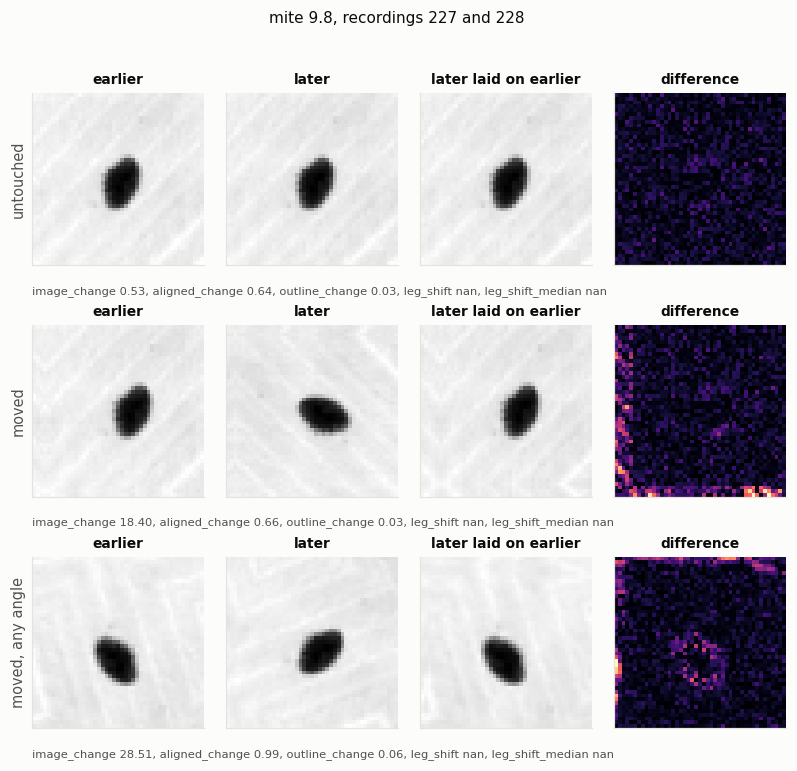

In [8]:
mites, at = np.nonzero(group["long_dead"])
values = found["moved"]["aligned_change"][mites, at]
pick = np.argsort(values)[len(values) // 2]
mite, at = int(mites[pick]), int(at[pick])
patches = mmc.patches_of(run, mite)
tracker = LegTracker()

def legs_in_image(frames):
    tracks = tracker.track(frames)
    return np.nanmean(tracks.xy, axis=1) + np.nanmean(tracks.centre, axis=0) if len(tracks) else np.zeros((0, 2))

fig, axes = plt.subplots(len(SHOWN), 4, figsize=(9, 2.5 * len(SHOWN)), gridspec_kw={"wspace": 0.05, "hspace": 0.35})
for row, condition in enumerate(SHOWN):
    pose = mmc.poses(condition, n_recordings, mite)
    earlier_frames, later_frames = mmc.move(patches[at], pose[at]), mmc.move(patches[at + 1], pose[at + 1])
    earlier, later = earlier_frames.mean(axis=0), later_frames.mean(axis=0)
    aligned, _turn = mmc.align(earlier, later)
    shown = [earlier, later, aligned, np.abs(earlier - aligned)]
    titles = ["earlier", "later", "later laid on earlier", "difference"]
    for column, (image, title) in enumerate(zip(shown, titles)):
        ax = axes[row, column]
        ax.imshow(image, cmap="magma" if column == 3 else "gray", vmin=0 if column == 3 else None, vmax=8 if column == 3 else None)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(title, fontsize=9)
    for points, color, ax in ((legs_in_image(earlier_frames), BLUE, axes[row, 0]),
                              (legs_in_image(later_frames), ORANGE, axes[row, 1])):
        ax.scatter(*points.T, s=40, facecolors="none", edgecolors=color, linewidths=1.2)
    measured = ", ".join(f"{name} {found[condition][name][mite, at]:.2f}" for name in mmc.MEASURES)
    axes[row, 0].set_ylabel(condition, fontsize=9.5)
    axes[row, 0].text(0, -0.12, measured, transform=axes[row, 0].transAxes, fontsize=7.5, color=MUTED, va="top")
fig.suptitle(f"mite {run['ids'][mite]}, recordings {at} and {at + 1}", fontsize=10, color=INK)
plt.show()

## Every mite, and the survival

One row per mite, sorted by its death by the labels (the recording after its last labelled movement); the colour is `outline_change` from each recording to the next. Over it, on the right-hand axis, the Kaplan-Meier survival: by the labels (black, the ground truth, with its 95% interval), and by the outline change (orange, dashed). With the rows sorted by death, the black curve runs along the left edge of the empty part: what is coloured right of it are changes between recordings after the mite's last labelled movement.

For the orange curve a mite counts as moving in a recording when the outline changed in the two pairs of recordings that end there: the limit is what 99% of the long-dead pairs stay under, so a single pair over it comes once in about 100 by chance, and a mite followed for 200 recordings after its death would most often show one. The mites never labelled moving are not in the survival and are left out (as the app does).

The same plot for the mites moved on purpose (whole pixels and quarter turns) follows: if the outline change survives the move, it looks the same.

57 mites in the survival, 2 never labelled moving left out; limit of a changed pair 0.064 px


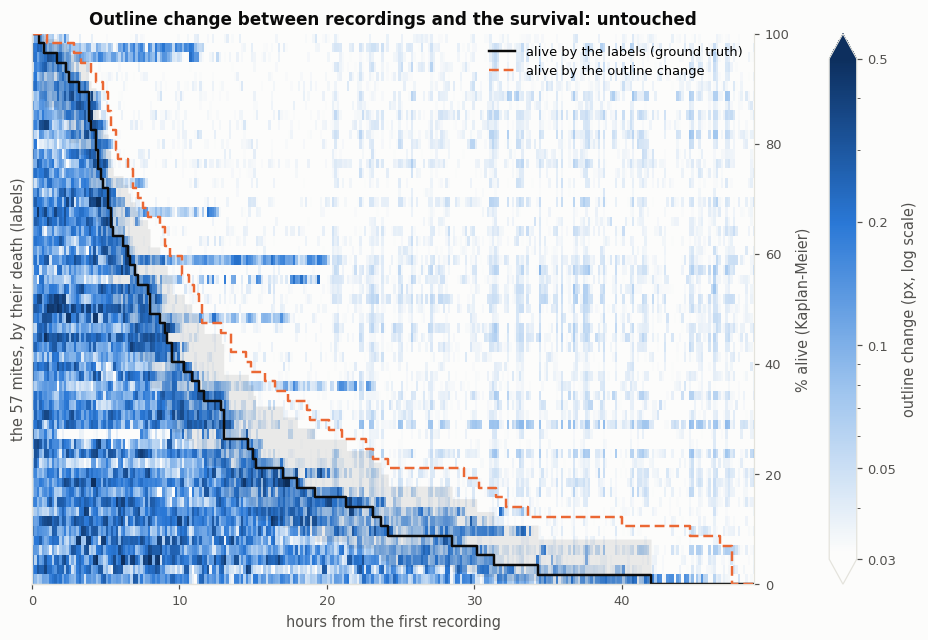

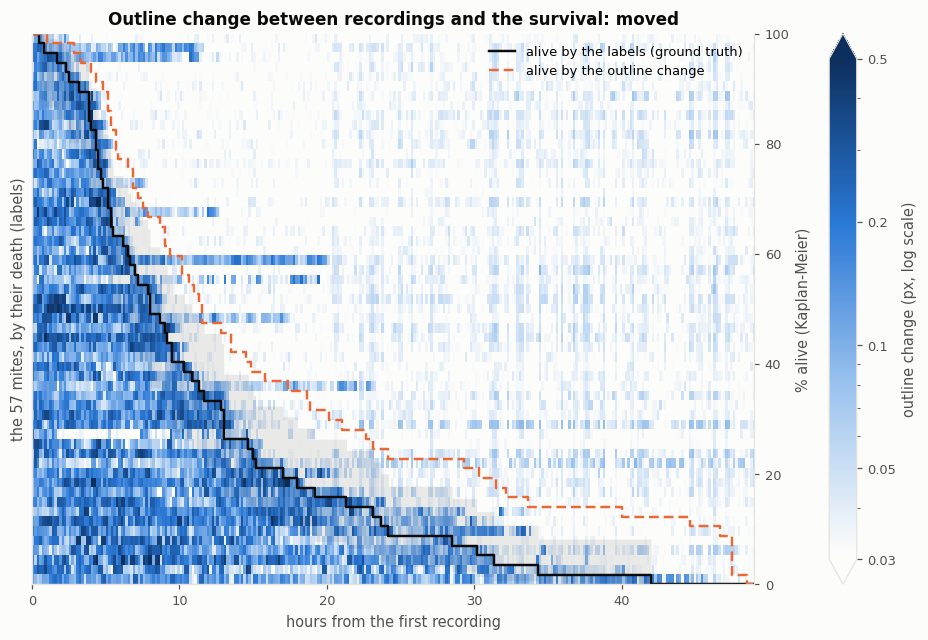

In [9]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from classes.survival import SurvivalAnalysis

LIMIT = np.nanpercentile(found["untouched"]["outline_change"][group["long_dead"]], 99)
survival = SurvivalAnalysis(run["times"])
study = np.flatnonzero(run["moving"].any(axis=1))
order = study[np.argsort([survival.alive_until(list(run["moving"][mite])) for mite in study], kind="stable")]
hours = run["times"] / 60
shade = LinearSegmentedColormap.from_list("change", ["#fcfcfb", "#9cc3ee", BLUE, "#0d2f5e"])
print(f"{len(study)} mites in the survival, {n_mites - len(study)} never labelled moving left out; "
      f"limit of a changed pair {LIMIT:.3f} px")

def outline_calls(change):
    # moving in a recording: the outline changed in both pairs that end there
    changed = change > LIMIT
    calls = np.zeros(run["moving"].shape, dtype=bool)
    calls[:, 2:] = changed[:, 1:] & changed[:, :-1]
    return calls

def raster(condition):
    change = found[condition]["outline_change"]
    fig, ax = plt.subplots(figsize=(11, 6.5))
    drawn = ax.imshow(np.clip(change[order], 1e-3, None), aspect="auto", cmap=shade,
                      norm=LogNorm(vmin=np.nanmedian(change[group["long_dead"]]), vmax=0.5),
                      interpolation="nearest", extent=(hours[0], hours[-1], len(order), 0))
    ax.set(xlabel="hours from the first recording", ylabel=f"the {len(order)} mites, by their death (labels)", yticks=[],
           xlim=(hours[0], hours[-1]), title=f"Outline change between recordings and the survival: {condition}")
    ax.grid(visible=False)
    km = ax.twinx()
    truth = [list(run["moving"][mite]) for mite in study]
    interval = survival.alive_ci(truth)
    km.fill_between(hours, np.array(interval["low"], dtype=float), np.array(interval["high"], dtype=float),
                    step="post", color=INK, alpha=0.08, linewidth=0)
    km.step(hours, np.array(survival.alive_percent(truth), dtype=float), where="post", color=INK, linewidth=1.6,
            label="alive by the labels (ground truth)")
    calls = outline_calls(change)
    km.step(hours, np.array(survival.alive_percent([list(calls[mite]) for mite in study]), dtype=float), where="post",
            color=ORANGE, linewidth=1.6, linestyle=(0, (4, 2)), label="alive by the outline change")
    km.set_ylim(0, 100)
    km.set_ylabel("% alive (Kaplan-Meier)")
    km.grid(visible=False)
    km.spines["right"].set_visible(True)
    km.legend(loc="upper right")
    bar = fig.colorbar(drawn, ax=ax, pad=0.08, label="outline change (px, log scale)", extend="both")
    bar.set_ticks([0.03, 0.05, 0.1, 0.2, 0.5], labels=["0.03", "0.05", "0.1", "0.2", "0.5"])
    plt.show()
    return calls

calls = {condition: raster(condition) for condition in ("untouched", "moved")}

In [10]:
def lt50(movings):
    found_lt50 = survival.lt50(movings)["estimate"]
    return np.nan if found_lt50 is None else found_lt50 / 60

truth = [list(run["moving"][mite]) for mite in study]
deaths = np.array([survival.alive_until(moving) for moving in truth])
rows = {"labels (ground truth)": {"LT50 (hours)": lt50(truth)}}
for condition, called in calls.items():
    by_outline = [list(called[mite]) for mite in study]
    later = np.array([survival.alive_until(moving) for moving in by_outline]) - deaths
    rows[f"outline change, {condition}"] = {
        "LT50 (hours)": lt50(by_outline),
        "death later than the labels' (recordings, median)": float(np.median(later)),
        "same recording or earlier": float(np.mean(later <= 0)),
        "more than 6 recordings (1 hour) later": float(np.mean(later > 6)),
        "more than 36 recordings (6 hours) later": float(np.mean(later > 36))}
display(pd.DataFrame(rows).T.style.format("{:.2f}", na_rep="")
        .format("{:.0%}", subset=["same recording or earlier", "more than 6 recordings (1 hour) later",
                                   "more than 36 recordings (6 hours) later"], na_rep=""))

,LT50 (hours),"death later than the labels' (recordings, median)",same recording or earlier,more than 6 recordings (1 hour) later,more than 36 recordings (6 hours) later
labels (ground truth),8.00,,,,
"outline change, untouched",11.50,7.00,0%,56%,26%
"outline change, moved",11.50,7.00,0%,56%,28%


## What this does not test

- **A real move.** A mite moved here takes the plate's texture around it with it. A move by whole pixels also keeps the mite on the same grid of pixels, where a real one lands it a fraction of a pixel elsewhere (the plate's own drift between recordings, which the untouched pairs have, is of that kind); a move by any angle blurs it instead. A mite pushed on the real plate leaves the texture where it was. The image comparisons keep to the mite and 3 px around it for that reason, but some of the texture is in there. Only a run with mites known to be dead (killed by freezing) and the box opened and the mites nudged on purpose can say what a real move does.
- **A dead mite's legs pushed.** A brush can bend a dead mite's legs or turn it on its back. No measure here can tell that from a movement: the pair across an opening should be left out of the analysis whatever the measure (as a disturbed recording is), and the recording after it becomes the new reference.
- **A move out of the saved ROI.** A live run keeps 32 px around each mite's box (`classes/roi_recordings.py`). The moves here stay within 6 px. A mite pushed further leaves its saved video, and only a new detection after the opening finds it again.
- **Another run.** One run, one plate, one camera. The leg tracker's settings were chosen on this run (`leg_tracking.ipynb`).